# Kapitel 3

## Frågor

### 1. Vad kännetecknar regressionsproblem? Ge några exempel på tillämpningsområden.

In a regression problem the target y is a continuous number, not a category. So the question is "what value?" rather than "which class?".

Examples: predicting house prices, salary from years of experience, tomorrow's temperature, next month's sales in a store, a car's fuel consumption, or a patient's blood pressure.

### 2. Förklara utvärderingsmåtten RMSE, MSE och MAE.

All three measure how far the predictions of a regression model are from the true values, in slightly different ways.

- **MSE (Mean Squared Error)**: the average of the squared differences between actual and predicted values. Squaring means large errors count much more than small ones, and positive and negative errors don't cancel out. The unit is squared (e.g. kr²), which is hard to interpret.
- **RMSE (Root Mean Squared Error)**: the square root of MSE. It's back in the original unit, and still gives large errors extra weight.
- **MAE (Mean Absolute Error)**: the average of the absolute errors. Every error counts linearly, so a few very large errors affect it less than they affect RMSE.

So MAE is less sensitive to outliers, while RMSE and MSE penalize large errors more, which is useful when large errors are especially bad.

### 3. Om vi ska rangordna olika modeller, spelar det någon roll om RMSE eller MSE används? Varför?

No. The square root is an increasing function for non-negative numbers, so if model A has lower MSE than model B, it also has lower RMSE. The ranking is the same.

The reason to prefer RMSE is that it's in the original unit and easier to interpret, not that it changes which model is best.

### 4. Förklara mycket översiktligt vad gradient descent är.

Gradient descent is an optimization algorithm for finding the parameters (e.g. weights) that minimize a cost function such as MSE.

Start with some parameter values, calculate the gradient (slope) of the cost function at that point, and take a step in the opposite direction, downhill. Repeat until the cost stops decreasing, which should be close to a minimum.

The step size is the learning rate: too small and it takes very long, too large and it can overshoot and never converge.

### 5. Vad är the bias variance trade-off? Varför är mer komplexa modeller inte alltid bättre?

Bias is error from a model that is too simple and misses real patterns (underfitting). Variance is error from a model that is too sensitive to the specific training data and picks up noise (overfitting).

These usually move in opposite directions: a very simple model has high bias and low variance, a very flexible model has low bias and high variance. The expected error is roughly bias² + variance + irreducible noise, so we look for a level of complexity that keeps the total low, not the most complex model.

That's why more complex models aren't always better: beyond some point the extra flexibility fits noise in the training data, which makes the results on new data worse even though the training error goes down.

### 6. Några vanligt förekommande modeller för regressionsproblem är enligt nedan. Förklara översiktligt hur respektive modell fungerar. Läs även igenom respektive modells dokumentation, notera att du inte behöver förstå alla detaljer från dokumentationen men det är bra att ha läst igenom den.

#### a) Linjär regression

Fits a straight line (or a hyperplane with several features) through the data: y = b0 + b1·x1 + b2·x2 + ... The coefficients are chosen to minimize the sum of squared errors (least squares). It's simple, fast and easy to interpret, since each coefficient says how much y changes when that feature increases by one. It works best when the relationship is roughly linear.

#### b) Ridge regression

Same idea as linear regression but adds a penalty term (L2 regularization, the sum of squared weights) to the cost function. This shrinks the coefficients towards zero, but usually not exactly to zero, so unlike Lasso it doesn't really do feature selection. It helps against overfitting and is especially useful when features are correlated with each other (multicollinearity). The `alpha` hyperparameter controls how strong the penalty is, higher alpha means more shrinkage and a simpler model.

#### c) Lasso regression

Like Ridge but with L1 regularization (the sum of the absolute values of the weights). The difference is that Lasso can shrink some coefficients all the way to exactly zero, which removes those features from the model. So Lasso does feature selection, which is useful when only some of the features are expected to matter.

#### d) Elastic net

A combination of Ridge and Lasso that uses both the L1 and L2 penalties, with `l1_ratio` controlling the mix. It can do some feature selection like Lasso while being more stable like Ridge. It's useful when there are groups of correlated features, where Lasso on its own tends to pick one feature from the group and set the others to zero.

#### e) Support vector machines

SVR fits a function where errors smaller than `epsilon` are ignored (a "tube" around the prediction), and only points outside that tube are penalized. With kernels (for example RBF) it can model non-linear relationships, by working as if the data were mapped to a higher-dimensional space without computing that mapping explicitly (the kernel trick). It works well on small and medium datasets, but training gets slow on large datasets and it needs tuning of C, epsilon and the kernel.

#### f) Beslutsträd

A decision tree splits the data repeatedly on feature values, e.g. "horsepower > 150?", building a tree of if/else questions. Each split is chosen to reduce the error in the resulting groups. The prediction in a leaf is the average target value of the training rows that ended up there. Trees are easy to interpret and can capture non-linear relationships, but without limits (like `max_depth`) they grow very deep and overfit.

#### g) Ensemble learning

Ensemble learning combines several models to get a better result than any single one of them.

- **VotingRegressor**: trains several different models (for example linear regression, a decision tree and SVR) and averages their predictions.
- **BaggingRegressor**: trains the same kind of model several times, each on a random sample of the training data drawn with replacement (bootstrap), and averages the predictions. This reduces variance and works well for models that tend to overfit, like decision trees.

#### h) Random forest

Random forest is bagging with decision trees plus one extra step: at each split only a random subset of the features is considered. This makes the trees less similar to each other, so averaging them reduces variance more than plain bagging. It usually performs well with little tuning and overfits less than a single deep tree, but it's harder to interpret than a single tree.

### 7. Vad menas med white box modeller och black box modeller?

White box models are models where you can see why a prediction was made, like linear regression (look at the coefficients) or a single decision tree (follow the splits down to the leaf).

Black box models may perform well, but it's hard to explain a specific prediction, like a random forest with hundreds of trees or a neural network with millions of parameters. Tools like feature importance or SHAP values give some insight, but not as directly.

This matters in areas like medicine or lending, where decisions may have to be explained, legally or ethically, even if a black box model would perform somewhat better.

### 8. Vad är skillnaden mellan bagging och pasting?

Both train several copies of the same model on different random subsets of the training data and combine the predictions. The difference is how the subsets are sampled:

- **Bagging**: sampling with replacement (bootstrap), so the same row can appear several times in a subset and some rows not at all.
- **Pasting**: sampling without replacement, each row appears at most once in a subset.

Bagging is more common (it's the default in BaggingRegressor and what random forest uses), since sampling with replacement gives more variation between the models, which usually reduces variance more.

### 9. Förklara hur man kan tolka figur 3.1 på sidan 113.

Figure 3.1 shows simple linear regression as a scatter plot: the x-axis is Ålder (age), the y-axis is Inkomst (income), and the black dots are the observed data points (y_i). The blue line through the points is the model's predictions, ŷ = θ̂₀ + θ̂₁x, where θ̂₀ is the intercept (where the line crosses the y-axis) and θ̂₁ is the slope (marked by the triangle on the line).

The red vertical lines from each dot to the blue line are the residuals, e_i = y_i − ŷ_i, the difference between the actual value (y_i) and the predicted value (ŷ_i) for the same x. Points far from the line have long residuals, points close to the line short ones.

This is the idea of linear regression in one picture: we look for the line (the θ̂₀ and θ̂₁) that makes the red residuals as small as possible overall, which is what least squares does by minimizing the sum of the squared residuals.

### 10. Förklara hur man kan tolka figur 3.13 på sidan 140. Hur hänger den ihop med figur 3.14 på sidan 141?

Figure 3.13 shows the actual tree structure of a fitted decision tree (depth 2), drawn with `sklearn.tree.plot_tree`. Root node splits on `X2 <= 0.438` (800 samples, squared_error 6807). If True it goes to a node splitting on `X2 <= -0.755`, if False it goes to a node splitting on `X1 <= -0.654`. Each of those splits again into 2 leaf nodes, giving 4 leaves total, each leaf showing its own squared_error, sample count, and predicted value (ranging from -62.95 up to 62.80 across the 4 leaves).

Figure 3.14 shows the same tree but drawn geometrically instead: a 2D plot with X1 on one axis and X2 on the other, split into 4 rectangular regions by straight lines, colored by the predicted value in each region (a red/blue colormap from -80 to 80). The actual data points are scattered on top, colored by their true y value, so you can visually check how well the tree's box-shaped regions match the real pattern in the data.

How they connect: every split in the tree diagram (3.13) corresponds directly to one of the straight boundary lines in the geometric plot (3.14). The root split `X2 <= 0.438` is the horizontal line separating the top region from the bottom two, since X2 is on the vertical axis. Then the second-level split `X2 <= -0.755` further cuts the bottom region into two horizontal bands, while `X1 <= -0.654` cuts the top region into a left and right piece (a vertical line, since X1 is on the horizontal axis). So the 4 leaves in 3.13 are exactly the 4 colored rectangular regions in 3.14, decision trees only ever produce axis-aligned rectangular splits like this, that's why the regions all have straight horizontal/vertical edges instead of any diagonal or curved boundaries.

### 11. Vi har lärt oss utvärderingsmåtten RMSE, MSE och MAE. Ett annat utvärderingsmått är det som benämns för determinationskoefficienten eller R². Förklara vad det är för mått.

R² tells us how much of the variance in y the model explains, compared to always predicting the mean of y:

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

The top part is the sum of squared errors of our model, the bottom part is the sum of squared errors of a baseline that always predicts the average y.

R² = 1 means perfect predictions. R² = 0 means the model is exactly as good as always guessing the mean. R² can also be negative, when the model is worse than that baseline, and there is no lower limit.

R² is unitless, which makes it easier to read than RMSE when you don't know the scale of y. But that doesn't make R² values from different datasets directly comparable, since how much variance there is to explain differs between datasets.

### 13. Datasetet “hr_employee_data.xlsx” innehåller data kopplat till ett företags anställda. Gör en EDA och tillhörande analys, föreställ dig att ledningsgruppen på ett företag ska ta del av analysen. I denna uppgift ska ingen ML-modellering göras (det kommer göras i nästa kapitel). Syftet är dels att träna på att genomföra analyser dels att demonstrera hur mycket man kan göra även utan ML-modellering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("data/hr_employee_data.xlsx")
df.head()

,Emp_Id,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,IND02438,0.38,0.53,2,157,3,0,1,0,sales,low
1,IND28133,0.80,0.86,5,262,6,0,1,0,sales,medium
2,IND07164,0.11,0.88,7,272,4,0,1,0,sales,medium
3,IND30478,0.72,0.87,5,223,5,0,1,0,sales,low
4,IND24003,0.37,0.52,2,159,3,0,1,0,sales,low


In [2]:
df.shape

(14999, 11)

14999 rows (employees) and 11 columns. No missing values (checked with `df.isna().sum()`).

In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Emp_Id                 14999 non-null  str    
 1   satisfaction_level     14999 non-null  float64
 2   last_evaluation        14999 non-null  float64
 3   number_project         14999 non-null  int64  
 4   average_montly_hours   14999 non-null  int64  
 5   time_spend_company     14999 non-null  int64  
 6   Work_accident          14999 non-null  int64  
 7   left                   14999 non-null  int64  
 8   promotion_last_5years  14999 non-null  int64  
 9   Department             14999 non-null  str    
 10  salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(3)
memory usage: 1.3 MB


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


First, how many of the employees in the data have left:

In [4]:
df["left"].value_counts(normalize=True)

left
0    0.761917
1    0.238083
Name: proportion, dtype: float64

23.8% of the rows have `left` = 1. The file doesn't say over what time period people left, so this isn't a yearly turnover rate, and I have no benchmark to say whether it's high. It's still a large enough group to be worth understanding.

In [5]:
df.groupby("left")[["satisfaction_level", "last_evaluation", "average_montly_hours", "time_spend_company", "number_project"]].mean().round(2)

,satisfaction_level,last_evaluation,average_montly_hours,time_spend_company,number_project
left,,,,,
0,0.67,0.72,199.06,3.38,3.79
1,0.44,0.72,207.42,3.88,3.86


People who left have a much lower average satisfaction_level (0.44 vs 0.67). That's the biggest difference in this table. They also stayed slightly longer on average (3.88 vs 3.38 years) and worked slightly more hours.

In [6]:
df.groupby("salary")["left"].mean().round(3).sort_values()

salary
high      0.066
medium    0.204
low       0.297
Name: left, dtype: float64

There's a clear pattern with salary: 6.6% of employees with high salary left, compared to 20.4% for medium and 29.7% for low. This is an association, the data doesn't show that low salary is the reason people left, since salary is also related to other things like role and seniority.

In [7]:
df.groupby("Department")["left"].mean().sort_values(ascending=False).round(3)

Department
hr             0.291
accounting     0.266
technical      0.256
support        0.249
sales          0.245
marketing      0.237
IT             0.222
product_mng    0.220
RandD          0.154
management     0.144
Name: left, dtype: float64

HR (29.1%) and accounting (26.6%) have the highest share of leavers, management (14.4%) and R&D (15.4%) the lowest. That could be worth looking into, but the data doesn't show why the departments differ.

In [8]:
display(df.groupby("Work_accident")["left"].mean().round(3))
display(df.groupby("promotion_last_5years")["left"].mean().round(3))
display(df.groupby("Work_accident")["time_spend_company"].mean().round(2))
display(df["promotion_last_5years"].mean().round(3))

Work_accident
0    0.265
1    0.078
Name: left, dtype: float64

promotion_last_5years
0    0.242
1    0.060
Name: left, dtype: float64

Work_accident
0    3.50
1    3.51
Name: time_spend_company, dtype: float64

np.float64(0.021)

Employees who had a work accident left less often (7.8% vs 26.5%). I don't have a good explanation for that, and it's not because they had been at the company longer (average tenure is 3.50 vs 3.51 years). Employees promoted in the last 5 years also left less often (6.0% vs 24.2%), but only about 2% of employees were promoted, so that group is small.

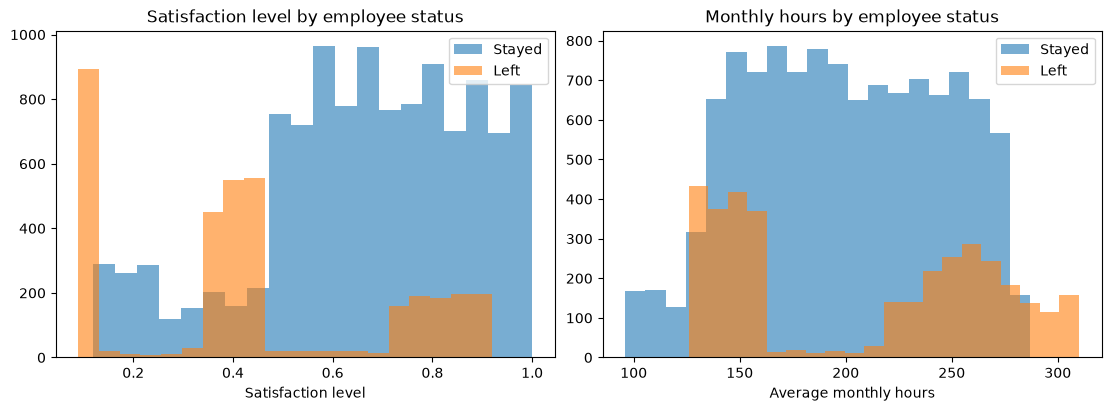

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

axs[0].hist(df.loc[df["left"] == 0, "satisfaction_level"], bins=20, alpha=0.6, label="Stayed")
axs[0].hist(df.loc[df["left"] == 1, "satisfaction_level"], bins=20, alpha=0.6, label="Left")
axs[0].set_xlabel("Satisfaction level")
axs[0].set_title("Satisfaction level by employee status")
axs[0].legend()

axs[1].hist(df.loc[df["left"] == 0, "average_montly_hours"], bins=20, alpha=0.6, label="Stayed")
axs[1].hist(df.loc[df["left"] == 1, "average_montly_hours"], bins=20, alpha=0.6, label="Left")
axs[1].set_xlabel("Average monthly hours")
axs[1].set_title("Monthly hours by employee status")
axs[1].legend()

The satisfaction histogram for people who left isn't just shifted lower, it has three separate groups: very low satisfaction (below 0.2), around 0.35-0.5, and fairly high (0.7-0.9). The hours histogram for leavers has two groups: around 130-170 hours and around 210-310 hours.

So people who left don't look like one homogeneous group. One possible interpretation is that some leave because they're unhappy and some leave despite being fairly satisfied, maybe because of a high workload or better offers elsewhere. That's a hypothesis, this data doesn't tell us the reasons.

In [10]:
corr = df.corr(numeric_only=True)["left"].sort_values()
corr

satisfaction_level      -0.388375
Work_accident           -0.154622
promotion_last_5years   -0.061788
last_evaluation          0.006567
number_project           0.023787
average_montly_hours     0.071287
time_spend_company       0.144822
left                     1.000000
Name: left, dtype: float64

satisfaction_level has the strongest correlation with leaving (-0.39), followed by Work_accident (-0.15), time_spend_company (+0.14) and promotion_last_5years (-0.06). number_project, last_evaluation and average_montly_hours have correlations close to zero.

Pearson correlation only measures linear relationships though. The histograms above show that hours has two separate groups of leavers, both low and high hours, which a linear correlation would mostly cancel out. So a near-zero correlation doesn't mean the feature is unrelated to leaving.

**Summary for management:**
- 23.8% of employees in the data have left. The time period isn't specified, so I can't say how this compares to a normal turnover rate.
- Low satisfaction is the strongest single signal. But people who left form several groups: some with very low satisfaction, some with medium and some with fairly high satisfaction. Workload (hours, projects) also looks different between these groups.
- Employees with low salary left much more often (29.7%) than those with high salary (6.6%), and promoted employees left less often. These are associations, not proven causes.
- HR and accounting have the highest share of leavers, management and R&D the lowest.
- Suggestion: rather than one general effort to raise satisfaction, look separately at the different groups of leavers, and check workload and career development for the fairly satisfied group that still left. Interviews or exit surveys would be needed to find out the actual reasons.

### 16. I denna uppgift ska du göra ett komplett ML-flöde där du modellerar diamantpriser som finns tillgängliga i datasetet “diamonds.csv”. Du kan läsa mer om datasetet här: https://www.kaggle.com/datasets/shivam2503/diamonds

53940 rows and 10 columns (carat, cut, color, clarity, depth, table, price, x, y, z) plus an index column, `Unnamed: 0`, which I drop.

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

diamonds = pd.read_csv("data/diamonds.csv")
diamonds.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [12]:
diamonds.info()
diamonds.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  str    
 3   color       53940 non-null  str    
 4   clarity     53940 non-null  str    
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 4.5 MB


Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

No missing values, but that doesn't mean the data is clean. Checking for impossible values and duplicates:

In [13]:
diamonds = diamonds.drop(columns="Unnamed: 0")

zero_dims = (diamonds[["x", "y", "z"]] == 0).any(axis=1)
extreme_dims = (diamonds[["x", "y", "z"]] > 20).any(axis=1)
print("rows with a zero dimension:", zero_dims.sum())
print("exact duplicate rows:", diamonds.duplicated().sum())
display(diamonds[extreme_dims])

rows with a zero dimension: 20
exact duplicate rows: 146


,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


A diamond can't have a size of 0 mm, so those rows are errors. The three extreme rows have one dimension of 31.8 or 58.9 mm while the other two dimensions and the carat are normal, which looks like typing errors. I remove these rows, and also the exact duplicates so the same diamond can't end up in both the training and the test data.

In [14]:
diamonds = diamonds[~zero_dims & ~extreme_dims].drop_duplicates()
print("rows left:", len(diamonds))

cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

encoder = OrdinalEncoder(categories=[cut_order, color_order, clarity_order])
diamonds[["cut", "color", "clarity"]] = encoder.fit_transform(diamonds[["cut", "color", "clarity"]])

X = diamonds.drop(columns="price")
y = diamonds["price"]

rows left: 53772


I used ordinal encoding instead of one-hot since cut, color and clarity all have a quality order (Fair < Good < ... < Ideal etc), so they are ordinal rather than nominal.

In [15]:
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)

In [16]:
lin_reg = LinearRegression().fit(X_train, y_train)
lin_pred = lin_reg.predict(X_val)

rf_reg = RandomForestRegressor(random_state=42).fit(X_train, y_train)
rf_pred = rf_reg.predict(X_val)

for name, pred in [("Linear Regression", lin_pred), ("Random Forest", rf_pred)]:
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    r2 = r2_score(y_val, pred)
    print(f"{name}: RMSE={rmse:.2f}, R2={r2:.3f}")

Linear Regression: RMSE=1232.23, R2=0.906
Random Forest: RMSE=552.92, R2=0.981


On the validation data random forest had less than half the RMSE of linear regression (about 553 vs 1232) and R² 0.981 vs 0.906. Price doesn't increase linearly with carat, it rises faster for bigger diamonds, and a tree model can follow that shape while plain linear regression can't.

In [17]:
hyper_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    hyper_params,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1,
)
grid.fit(X_train, y_train)
print(grid.best_params_)

best_pred = grid.best_estimator_.predict(X_val)
print("Tuned RMSE:", np.sqrt(mean_squared_error(y_val, best_pred)))

{'max_depth': 20, 'n_estimators': 200}


Tuned RMSE: 552.8664478621162


Tuning made almost no difference: the best combination (max_depth=20, 200 trees) got validation RMSE 552.87, compared to 552.92 for the default random forest. The defaults were already close to the best of the settings I tried.

In [18]:
final_model = grid.best_estimator_.__class__(**grid.best_params_, random_state=42)
final_model.fit(X_train_full, y_train_full)

test_pred = final_model.predict(X_test)
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))
print("Test R2:", r2_score(y_test, test_pred))

Test RMSE: 522.9258247215671
Test R2: 0.9823959378460436


On the test set the final model (trained on train+val) got RMSE about 523 and R² 0.982. That's in line with the validation result, so the model generalizes well to data it hasn't seen.

In [19]:
production_model = RandomForestRegressor(**grid.best_params_, random_state=42)
production_model.fit(X, y)

importances = pd.Series(production_model.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.round(3)

carat      0.582
y          0.306
clarity    0.063
color      0.031
z          0.005
x          0.005
depth      0.003
table      0.002
cut        0.002
dtype: float64

This is the same workflow as in chapter 2: choose the model on validation data, retrain on train+val, estimate performance once on the test set, and finally retrain on all data for the model that would be used.

In the final model carat has the highest importance (about 0.58), followed by y (about 0.31), one of the size dimensions, which is strongly related to carat. clarity and color matter somewhat, while cut, table and depth contribute very little. Importance shows what the model uses for its splits, not causal effects, and correlated features like carat and y share the importance between them.